# **HYBRIDISATION & STATIC CONDENSATION**

1. **Setup:** good Helmholtz, our model problem
2. **How do DoFs couple?** And what that does to the **sparsity patterns** of our matrices
3. **Schur complements & static condensation**: eliminate the cell interiors, cell by cell
4. **Hybridisation**: break the space apart, glue it back together with a Lagrange multiplier, then condense everything else away
5. **Discussion:** which one, when?
6. *(If time...)* **Extras**

---

## **Install**

### Firedrake

In [1]:
try:
    import google.colab  # noqa: F401
except ImportError:
    from firedrake import *
else:
    try:
        from firedrake import *
    except ImportError:
        !wget "https://fem-on-colab.github.io/releases/firedrake-install-release-real.sh" -O "/tmp/firedrake-install.sh"
        !bash "/tmp/firedrake-install.sh"
        from firedrake import *

### Other

In [2]:
import json
import time
import uuid

import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from IPython.display import HTML, display
from finat.ufl import BrokenElement, FiniteElement, RestrictedElement

---

## **General functions**

### Matrices

In [3]:
def to_scipy(A):
    """Convert an assembled Firedrake matrix to a scipy CSR matrix, one field after another."""
    M = A.petscmat
    if M.getType() != "nest":
        ii, jj, vv = M.getValuesCSR()
        return sp.csr_matrix((vv, jj, ii), shape=M.getSize())
    nr, nc = M.getNestSize()
    blocks = [[None]*nc for _ in range(nr)]
    for i in range(nr):
        for j in range(nc):
            B = M.getNestSubMatrix(i, j)
            ii, jj, vv = B.getValuesCSR()
            blocks[i][j] = sp.csr_matrix((vv, jj, ii), shape=B.getSize())
    return sp.bmat(blocks, format="csr")


def assemble_scipy(a, bcs=None):
    """Assemble a bilinear form straight to scipy."""
    W = a.arguments()[0].function_space()
    return to_scipy(assemble(a, bcs=bcs, mat_type="nest" if len(W) > 1 else "aij"))


def nnz(A):
    """Number of entries of a matrix that aren't round-off."""
    A = A.tocsr() if sp.issparse(A) else sp.csr_matrix(A)
    return int((abs(A.data) > 1e-12*abs(A.data).max()).sum())

### DoF layouts

In [4]:
def _base_element(fe):
    """Strip a 'broken' wrapper off a FInAT element, returning (element, is_broken)."""
    if type(fe).__name__ == "DiscontinuousElement":
        return fe.element, True
    return fe, False


def _ref_positions(fe):
    """Where to draw each local DoF on the reference triangle (0,0), (1,0), (0,1).

    Point evaluations are drawn at their point. Moment DoFs (e.g. higher-order CR)
    are spread over the entity they belong to: Gauss points along an edge, a small
    lattice around the centroid for the cell interior.
    """
    base, _ = _base_element(fe)
    funcs = base.fiat_equivalent.dual_basis()
    verts = np.array([[0.0, 0.0], [1.0, 0.0], [0.0, 1.0]])
    edges = {0: (1, 2), 1: (0, 2), 2: (0, 1)}
    centroid = verts.mean(axis=0)
    pos = np.zeros((len(funcs), 2))
    for dim, ents in base.entity_dofs().items():
        for e, dofs in ents.items():
            k = len(dofs)
            for i, d in enumerate(dofs):
                pts = np.array(list(funcs[d].get_point_dict().keys()))
                if len(pts) == 1:
                    pos[d] = pts[0]
                elif dim == 1:
                    a, b = verts[edges[e][0]], verts[edges[e][1]]
                    t = (np.polynomial.legendre.leggauss(k)[0][i] + 1) / 2
                    pos[d] = a + t*(b - a)
                else:
                    q = int(round((np.sqrt(8*k + 1) - 3) / 2))
                    lattice = [(r/q, s/q) if q else (1/3, 1/3) for r in range(q + 1) for s in range(q + 1 - r)]
                    pos[d] = centroid + 0.45*(np.array(lattice[i]) - centroid)
    return pos


def dof_positions(V, shrink=0.72):
    """Physical positions of every DoF of a scalar space V on a triangle mesh.

    DoFs of a broken element are pulled towards their cell's centroid, so that the
    copies of a DoF that used to be shared show up on either side of the facet.
    """
    mesh = V.mesh()
    _, broken = _base_element(V.finat_element)
    ref = _ref_positions(V.finat_element)
    X = mesh.coordinates.dat.data_ro
    cell_verts = mesh.coordinates.cell_node_map().values
    cnm = V.cell_node_map().values
    pos = np.full((V.dim(), 2), np.nan)
    for c in range(cnm.shape[0]):
        x0, x1, x2 = X[cell_verts[c]]
        phys = x0 + np.outer(ref[:, 0], x1 - x0) + np.outer(ref[:, 1], x2 - x0)
        if broken:
            centre = (x0 + x1 + x2) / 3
            phys = centre + shrink*(phys - centre)
        for i, g in enumerate(cnm[c]):
            if np.isnan(pos[g, 0]):
                pos[g] = phys[i]
    return pos


def entity_dims(V):
    """Dimension of the mesh entity each DoF of a scalar space V belongs to."""
    base, _ = _base_element(V.finat_element)
    loc = np.empty(V.finat_element.space_dimension(), dtype=int)
    for dim, ents in base.entity_dofs().items():
        for dofs in ents.values():
            loc[list(dofs)] = dim
    out = np.empty(V.dim(), dtype=int)
    for nodes in V.cell_node_map().values:
        out[nodes] = loc
    return out


def mesh_edges(mesh):
    """Vertex coordinates and the list of edges, for drawing a triangle mesh."""
    X = mesh.coordinates.dat.data_ro
    edges = set()
    for a, b, c in mesh.coordinates.cell_node_map().values:
        for e in [(a, b), (b, c), (a, c)]:
            edges.add(tuple(sorted(int(i) for i in e)))
    return X, sorted(edges)

### Coupling diagrams

In [5]:
COLOURS = ["#578ACC", "#B3532A", "#5E9E6E", "#8E6BB3"]

_WIDGET_JS = r"""
(function() {
  const data = __DATA__;
  const root = document.getElementById("__ID__");
  const svg = root.querySelector("svg");
  const info = root.querySelector(".info");
  const NS = "http://www.w3.org/2000/svg";
  const S = data.size, pad = 16;
  const X = x => pad + x*(S - 2*pad), Y = y => S - pad - y*(S - 2*pad);
  for (const [a, b] of data.edges) {
    const l = document.createElementNS(NS, "line");
    l.setAttribute("x1", X(data.verts[a][0])); l.setAttribute("y1", Y(data.verts[a][1]));
    l.setAttribute("x2", X(data.verts[b][0])); l.setAttribute("y2", Y(data.verts[b][1]));
    l.setAttribute("stroke", "#999"); l.setAttribute("stroke-width", 1.2);
    svg.appendChild(l);
  }
  const dots = data.dofs.map((d, i) => {
    const c = document.createElementNS(NS, "circle");
    c.setAttribute("cx", X(d[0])); c.setAttribute("cy", Y(d[1]));
    c.setAttribute("r", data.radius); c.setAttribute("fill", data.colours[d[2]]);
    c.setAttribute("stroke", "white"); c.setAttribute("stroke-width", 1);
    c.style.transition = "opacity 0.15s";
    c.addEventListener("click", ev => { ev.stopPropagation(); select(i); });
    svg.appendChild(c);
    return c;
  });
  let current = null;
  function reset() {
    current = null;
    dots.forEach(c => { c.style.opacity = 1; c.setAttribute("stroke", "white"); c.setAttribute("stroke-width", 1); });
    info.textContent = "Click a DoF to see what it couples to.";
  }
  function select(i) {
    if (current === i) { reset(); return; }
    current = i;
    const nbrs = new Set(data.adj[i]);
    dots.forEach((c, j) => {
      const on = (j === i) || nbrs.has(j);
      c.style.opacity = on ? 1 : 0.12;
      c.setAttribute("stroke", j === i ? "black" : "white");
      c.setAttribute("stroke-width", j === i ? 2.5 : 1);
    });
    const counts = data.fields.map(() => 0);
    nbrs.forEach(j => counts[data.dofs[j][2]] += 1);
    const parts = data.fields.map((f, k) => counts[k] + " " + f).filter((_, k) => counts[k] > 0 || data.fields.length === 1);
    info.textContent = "This " + data.fields[data.dofs[i][2]] + " DoF couples to " + nbrs.size + " others: " + parts.join(", ") + ".";
  }
  svg.addEventListener("click", reset);
  reset();
})();
"""


def coupling_pattern(a):
    """Which DoFs couple, as a sparse 0/1 matrix (one field after another): two DoFs
    couple when they share a cell (a facet DoF belongs to the cells either side),
    provided the form couples their two spaces at all."""
    W = a.arguments()[0].function_space()
    subspaces = [W.sub(i).collapse() for i in range(len(W))] if len(W) > 1 else [W]
    offsets = np.cumsum([0] + [V.dim() for V in subspaces])
    A = assemble_scipy(a).tocsr()
    rows, cols = [], []
    for i, Vi in enumerate(subspaces):
        for j, Vj in enumerate(subspaces):
            if abs(A[offsets[i]:offsets[i + 1], offsets[j]:offsets[j + 1]]).sum() > 0:
                ci = Vi.cell_node_map().values + offsets[i]
                cj = Vj.cell_node_map().values + offsets[j]
                rows.append(np.repeat(ci, cj.shape[1], axis=1).ravel())
                cols.append(np.tile(cj, (1, ci.shape[1])).ravel())
    rows, cols = np.concatenate(rows), np.concatenate(cols)
    P = sp.csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(offsets[-1], offsets[-1]))
    P.data[:] = 1
    return P


def coupling_widget(a, title="", fields=None, size=420, radius=None):
    """Draw the DoFs of a bilinear form's space on its mesh. Click a DoF to highlight
    every DoF it couples to: two DoFs couple when they share a cell (a facet DoF belongs
    to the cells either side), provided the form couples their two spaces at all."""
    W = a.arguments()[0].function_space()
    subspaces = [W.sub(i).collapse() for i in range(len(W))] if len(W) > 1 else [W]
    mesh = subspaces[0].mesh()
    fields = fields or [V.ufl_element().shortstr().split("(")[0] for V in subspaces]
    pos = np.vstack([dof_positions(V) for V in subspaces])
    field = np.concatenate([np.full(V.dim(), k) for k, V in enumerate(subspaces)])
    P = coupling_pattern(a)
    adj = [[int(j) for j in P.indices[P.indptr[i]:P.indptr[i + 1]] if j != i] for i in range(P.shape[0])]
    X, edges = mesh_edges(mesh)
    lo, hi = X.min(axis=0), X.max(axis=0)
    scale = (hi - lo).max()
    norm = lambda P: ((P - lo) / scale).round(4).tolist()
    data = {
        "size": size,
        "radius": radius or max(3.0, min(7.0, 0.9*size / np.sqrt(len(pos)))),
        "verts": norm(X),
        "edges": edges,
        "dofs": [p + [int(f)] for p, f in zip(norm(pos), field)],
        "adj": adj,
        "fields": fields,
        "colours": COLOURS,
    }
    uid = "w" + uuid.uuid4().hex[:10]
    legend = " &nbsp; ".join(
        f'<span style="color:{COLOURS[k]}; font-size:16px">&#9679;</span> {f} ({V.dim()} DoFs)'
        for k, (f, V) in enumerate(zip(fields, subspaces)))
    html = (
        f'<div id="{uid}" style="font-family: sans-serif; background: #fff; color: #222; padding: 10px; '
        f'display: inline-block; border: 1px solid #ddd; border-radius: 6px">'
        f'<div style="font-weight: bold; margin-bottom: 4px">{title}</div>'
        f'<svg width="{size}" height="{size}" style="cursor: pointer"></svg>'
        f'<div style="font-size: 13px">{legend}</div>'
        f'<div class="info" style="font-size: 13px; min-height: 1.4em; margin-top: 4px"></div>'
        f'</div><script>{_WIDGET_JS.replace("__DATA__", json.dumps(data)).replace("__ID__", uid)}</script>'
    )
    display(HTML(html))

### Model problem

In [6]:
def helmholtz(V):
    """Good Helmholtz, -Δu + u = f, as a bilinear form on V."""
    u, v = TrialFunction(V), TestFunction(V)
    return (inner(grad(u), grad(v)) + u*v)*dx


def forcing(mesh):
    """The right-hand side f of the model problem."""
    x, y = SpatialCoordinate(mesh)
    return sin(3*pi*x)*exp(y) + 1


ORIENTATION = (1.0, 2.0**0.5)  # parallel to no facet of the meshes used here


def jump_s(v, mesh):
    """Jump [[v]] = v+ - v- across a facet, with '+' the side whose outward normal
    points along ORIENTATION. Slate assembles facet integrals cell by cell, so the sign
    of the jump has to be fixed by the facet alone, not by which cell UFL calls '+'."""
    n = FacetNormal(mesh)
    e = as_vector(ORIENTATION)
    return v('+')*sign(dot(n('+'), e)) + v('-')*sign(dot(n('-'), e))

### Sparsity patterns & Schur complements

In [7]:
def plot_sparsity(p=3, nx=4):
    """Spy CG_p Helmholtz in Firedrake's ordering, then with DoFs sorted by entity."""
    mesh = UnitSquareMesh(nx, nx)
    V = FunctionSpace(mesh, "CG", p)
    A = assemble_scipy(helmholtz(V))
    dims = entity_dims(V)
    perm = np.argsort(dims, kind="stable")
    fig, axs = plt.subplots(1, 2, figsize=(11, 5.5))
    ms = max(0.5, 60 / V.dim())
    axs[0].spy(A, markersize=ms, color=COLOURS[0], markeredgewidth=0)
    axs[0].set_title("Firedrake's ordering")
    axs[1].spy(A[perm][:, perm], markersize=ms, color=COLOURS[0], markeredgewidth=0)
    axs[1].set_title("Sorted: vertices | edges | interiors")
    for c in np.cumsum(np.bincount(dims, minlength=3))[:-1]:
        axs[1].axhline(c - 0.5, color=COLOURS[1], lw=1)
        axs[1].axvline(c - 0.5, color=COLOURS[1], lw=1)
    for ax in axs:
        ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f"CG{p} on a {nx}x{nx} mesh: {V.dim()} DoFs, {nnz(A)} nonzeros")
    plt.show()


def schur_complement(A, elim):
    """S = A_ΓΓ - A_ΓI A_II^{-1} A_IΓ, eliminating the DoFs flagged in elim."""
    keep = ~elim
    AII = A[elim][:, elim].tocsc()
    AIG = A[elim][:, keep].tocsc()
    AGI = A[keep][:, elim]
    AGG = A[keep][:, keep]
    return (AGG - AGI @ spla.spsolve(AII, AIG)).tocsr()


def schur_demo(p=3, nx=6):
    """Eliminate the cell interiors of CG_p, then (for contrast) the vertices instead."""
    mesh = UnitSquareMesh(nx, nx)
    V = FunctionSpace(mesh, "CG", p)
    A = assemble_scipy(helmholtz(V))
    dims = entity_dims(V)
    perm = np.argsort(dims, kind="stable")
    fig, axs = plt.subplots(1, 3, figsize=(15, 5))
    axs[0].spy(A[perm][:, perm], markersize=max(0.3, 40 / V.dim()), color=COLOURS[0], markeredgewidth=0)
    axs[0].set_title(f"A (CG{p}, sorted by entity)")
    rows = []
    for ax, (label, elim) in zip(axs[1:], [("cell interiors", dims == 2), ("vertices", dims == 0)]):
        S = schur_complement(A, elim)
        ax.spy(S, markersize=max(0.3, 40 / S.shape[0]), precision=1e-12*abs(S).max(), color=COLOURS[0], markeredgewidth=0)
        ax.set_title(f"S, eliminating the {label}")
        rows.append((label, elim.sum(), S.shape[0], nnz(A[~elim][:, ~elim]), nnz(S), nnz(A[elim][:, elim])))
    for ax in axs:
        ax.set_xticks([]); ax.set_yticks([])
    plt.show()
    print(f"{'eliminating':>15} | {'# eliminated':>12} | {'size of S':>9} | {'nnz(A_ΓΓ)':>9} | {'nnz(S)':>7} | {'nnz(A_II)':>9}")
    for label, ne, ns, na, nS, nI in rows:
        print(f"{label:>15} | {ne:>12} | {ns:>9} | {na:>9} | {nS:>7} | {nI:>9}")


def schur_solve_check(p=3, nx=6):
    """Solve by eliminating interiors, back-substitute, and compare with a direct solve."""
    mesh = UnitSquareMesh(nx, nx)
    V = FunctionSpace(mesh, "CG", p)
    A = assemble_scipy(helmholtz(V)).tocsc()
    b = assemble(forcing(mesh)*TestFunction(V)*dx).dat.data_ro.copy()
    I = entity_dims(V) == 2
    G = ~I
    AII, AIG, AGI = A[I][:, I].tocsc(), A[I][:, G].tocsc(), A[G][:, I]
    S = schur_complement(A, I)
    uG = spla.spsolve(S.tocsc(), b[G] - AGI @ spla.spsolve(AII, b[I]))  # global
    uI = spla.spsolve(AII, b[I] - AIG @ uG)                               # local
    u = np.empty(V.dim())
    u[G], u[I] = uG, uI
    print(f"Solved a {S.shape[0]}x{S.shape[0]} system instead of {V.dim()}x{V.dim()}.")
    print(f"Difference from the direct solve: {np.abs(u - spla.spsolve(A, b)).max():.1e}")


def plot_hybrid_sparsity(p=3, nx=4):
    """CR_p sorted facets | interiors, against its hybridised form sorted DG_p (cell by
    cell) | multiplier. Patterns are which DoFs couple, as in the coupling diagrams."""
    mesh = UnitSquareMesh(nx, nx)
    V = FunctionSpace(mesh, "CR", p)
    P_cr = coupling_pattern(helmholtz(V))
    dims = entity_dims(V)
    perm_cr = np.argsort(dims, kind="stable")
    W, a, _ = hybrid_cr(mesh, p)
    P_h = coupling_pattern(a)
    n_dg = W.sub(0).dim()
    perm_h = np.concatenate([W.sub(0).collapse().cell_node_map().values.ravel(), n_dg + np.arange(W.sub(1).dim())])
    fig, axs = plt.subplots(1, 2, figsize=(11, 5.5))
    for ax, P, perm, cuts, title in [
            (axs[0], P_cr, perm_cr, np.cumsum(np.bincount(dims, minlength=3))[1:-1], f"CR{p}, sorted: facets | interiors"),
            (axs[1], P_h, perm_h, [n_dg], f"Hybridised: DG{p}, cell by cell | multiplier")]:
        ax.spy(P[perm][:, perm], markersize=max(0.8, 200 / P.shape[0]), color=COLOURS[0], markeredgewidth=0)
        for c in cuts:
            ax.axhline(c - 0.5, color=COLOURS[1], lw=1)
            ax.axvline(c - 0.5, color=COLOURS[1], lw=1)
        ax.set_title(f"{title}\n({P.shape[0]} DoFs)")
        ax.set_xticks([]); ax.set_yticks([])
    plt.show()

### Scaling experiments

In [8]:
def timed_solve(a, L, W, bcs, params, repeats=3):
    """Best-of wall time and iteration count for a solve from scratch (assembly, any
    local eliminations, and the global solve), after a warm-up run so that code
    generation isn't counted."""
    best = np.inf
    for k in range(repeats + 1):
        w = Function(W)
        solver = LinearVariationalSolver(LinearVariationalProblem(a, L, w, bcs=bcs), solver_parameters=params)
        t0 = time.perf_counter()
        solver.solve()
        if k > 0:
            best = min(best, time.perf_counter() - t0)
    ctx = solver.snes.ksp.getPC().getPythonContext() if params.get("pc_type") == "python" else None
    return best, (ctx.condensed_ksp if ctx else solver.snes.ksp).getIterationNumber()


def schur_nnz(W, a, boundary=False):
    """Size and nonzeros of the system left after eliminating field 0 cell by cell."""
    bcs = DirichletBC(W.sub(1).collapse(), 0, "on_boundary") if boundary else None
    A = Tensor(a)
    S = assemble(A.blocks[1, 1] - A.blocks[1, 0] * A.blocks[0, 0].inv * A.blocks[0, 1], bcs=bcs)
    return W.sub(1).dim(), nnz(to_scipy(S))


def report(p, full, reduced):
    (n0, z0, t0, i0), (n1, z1, t1, i1) = full, reduced
    print(f"p = {p}: unknowns {n0:>6} -> {n1:>6} | nonzeros {z0:>8} -> {z1:>8} | "
          f"iterations {i0:>4} -> {i1:>4} | time {t0:.3f}s -> {t1:.3f}s", flush=True)


def plot_scaling(rows, labels, solver, handle=None):
    """Unknowns, nonzeros, iterations and solve time against p, full against reduced.
    Draws into a display handle, so the figure can be redrawn as each p finishes."""
    ps = [r[0] for r in rows]
    panels = [(0, "unknowns in the global solve"), (1, "nonzeros in the global matrix"),
              (3, f"iterations ({solver})"), (2, "solve time (s)")]
    if solver == "lu":
        panels.pop(2)
    fig, axs = plt.subplots(1, len(panels), figsize=(4.4*len(panels), 4))
    for ax, (k, title) in zip(axs, panels):
        ax.semilogy(ps, [r[1][k] for r in rows], "o-", color=COLOURS[0], label=labels[0])
        ax.semilogy(ps, [r[2][k] for r in rows], "s-", color=COLOURS[1], label=labels[1])
        ax.set_xlabel("$p$"); ax.set_title(title); ax.set_xticks(ps)
        ax.grid(alpha=0.3)
    axs[0].legend()
    plt.tight_layout()
    if handle is None:
        handle = display(fig, display_id=True)
    else:
        handle.update(fig)
    plt.close(fig)
    return handle


def condensation_scaling(ps=range(1, 8), nx=32, solver="gamg"):
    """Global system size, nonzeros, iterations and solve time for CG_p, with and
    without static condensation."""
    mesh = UnitSquareMesh(nx, nx)
    rows, handle = [], None
    for p in ps:
        V = FunctionSpace(mesh, "CG", p)
        a, L = helmholtz(V), forcing(mesh)*TestFunction(V)*dx
        bc = DirichletBC(V, 0, "on_boundary")
        full = (V.dim(), nnz(assemble_scipy(a))) + timed_solve(a, L, V, bc, SOLVERS[solver])
        if p > 2:  # no cell-interior DoFs below cubics
            W, aW, LW, bcW = condensed_helmholtz(mesh, p)
            cond = schur_nnz(W, aW, boundary=True) + timed_solve(aW, LW, W, bcW, sc_params(solver))
        else:
            cond = full
        rows.append((p, full, cond))
        report(p, full, cond)
        handle = plot_scaling(rows, ("CG$_p$", "CG$_p$, condensed"), solver, handle)


def cr_problem(mesh, p):
    """Helmholtz on CR_p, u = 0 on the boundary."""
    V = FunctionSpace(mesh, "CR", p)
    return V, helmholtz(V), forcing(mesh)*TestFunction(V)*dx, DirichletBC(V, 0, "on_boundary")


def hybridisation_scaling(ps=(1, 3, 5, 7), nx=32, solver="gamg"):
    """Global system size, nonzeros, iterations and solve time for CR_p, directly and
    hybridised."""
    mesh = UnitSquareMesh(nx, nx)
    rows, handle = [], None
    for p in ps:
        V, aV, LV, bc = cr_problem(mesh, p)
        full = (V.dim(), nnz(assemble_scipy(aV))) + timed_solve(aV, LV, V, bc, SOLVERS[solver])
        W, a, L = hybrid_cr(mesh, p)
        hyb = schur_nnz(W, a) + timed_solve(a, L, W, None, sc_params(solver))
        rows.append((p, full, hyb))
        report(p, full, hyb)
        handle = plot_scaling(rows, ("CR$_p$", "CR$_p$, hybridised"), solver, handle)

### Checks

In [9]:
def naive_hybrid_cg_nullity(p=2, nx=3):
    """Break CG_p and glue it back with same-degree multipliers on every facet."""
    mesh = UnitSquareMesh(nx, nx)
    W = FunctionSpace(mesh, "DG", p) * FunctionSpace(mesh, "HDiv Trace", p)
    u, lam = TrialFunctions(W)
    v, mu = TestFunctions(W)
    a = (inner(grad(u), grad(v)) + u*v)*dx \
        + (jump_s(v, mesh)*lam('+') + jump_s(u, mesh)*mu('+'))*dS + (v*lam + u*mu)*ds
    s = np.linalg.svd(assemble_scipy(a).toarray(), compute_uv=False)
    print(f"Saddle-point matrix: {len(s)}x{len(s)}, nullity {int((s < 1e-10*s[0]).sum())}.")
    print(f"Number of vertices in the mesh: {mesh.num_vertices()}.")


def hybrid_check(ps=(1, 3, 5), nx=8):
    """Hybridised CR_p (condensed onto the multiplier) against CR_p solved directly."""
    mesh = UnitSquareMesh(nx, nx)
    for p in ps:
        W, a, L = hybrid_cr(mesh, p)
        w = Function(W)
        solve(a == L, w, solver_parameters=sc_params("lu"))
        V, aV, LV, bc = cr_problem(mesh, p)
        u = Function(V)
        solve(aV == LV, u, bcs=bc)
        print(f"p = {p}: ||u_hybrid - u_CR|| = {norm(w.subfunctions[0] - u):.1e}"
              f"   (multiplier: {W.sub(1).dim()} unknowns, CR: {V.dim()})")


def local_block_nullity(p=3, nx=3):
    """Nullity of the broken (cell-by-cell) matrix, with and without the zeroth-order term."""
    mesh = UnitSquareMesh(nx, nx)
    V = FunctionSpace(mesh, "DG", p)
    u, v = TrialFunction(V), TestFunction(V)
    for label, a in [("Poisson", inner(grad(u), grad(v))*dx), ("good Helmholtz", (inner(grad(u), grad(v)) + u*v)*dx)]:
        s = np.linalg.svd(assemble_scipy(a).toarray(), compute_uv=False)
        print(f"{label:>15}: nullity {int((s < 1e-10*s[0]).sum()):>3}   ({mesh.num_cells()} cells)")


def basis_comparison(p=5, nx=8):
    """Sparsity of one cell's blocks for two bases of the broken space, and their solutions."""
    cell = UnitTriangleMesh()
    mesh = UnitSquareMesh(nx, nx)
    sols = {}
    print(f"{'basis':>12} | {'stiffness':>9} | {'mass':>5} | {'u-λ coupling':>12}   (nonzeros on one cell)")
    for basis in ["CR", "integral"]:
        Vb = broken_space(cell, p, basis)
        M = FunctionSpace(cell, "HDiv Trace", p - 1)
        u, v, lam = TrialFunction(Vb), TestFunction(Vb), TrialFunction(M)
        K = assemble_scipy(inner(grad(u), grad(v))*dx)
        Mm = assemble_scipy(u*v*dx)
        B = assemble_scipy(v*lam*ds)
        print(f"{basis:>12} | {nnz(K):>4}/{K.shape[0]**2:<4} | {nnz(Mm):>5} | {nnz(B):>5}/{B.shape[0]*B.shape[1]:<6}")
        W, a, L = hybrid_cr(mesh, p, basis)
        w = Function(W)
        solve(a == L, w, solver_parameters=sc_params("lu"))
        sols[basis] = w.subfunctions[0]
    print(f"\nSame solution either way: ||u_CR-basis - u_integral-basis|| = {norm(sols['CR'] - sols['integral']):.1e}")


def flux_check(p=3, nxs=(4, 8, 16, 32)):
    """Compare the multiplier with -∇u·ν for a manufactured solution."""
    prev = None
    for nx in nxs:
        mesh = UnitSquareMesh(nx, nx)
        x, y = SpatialCoordinate(mesh)
        u_ex = sin(pi*x)*sin(pi*y)
        W, a, L = hybrid_cr(mesh, p, f=(2*pi**2 + 1)*u_ex)
        w = Function(W)
        solve(a == L, w, solver_parameters=sc_params("lu"))
        u, lam = w.subfunctions
        n = FacetNormal(mesh)
        nu = sign(dot(n('+'), as_vector(ORIENTATION)))*n('+')
        err_lam = sqrt(assemble((lam('+') + dot(grad(u_ex)('+'), nu))**2*dS + (lam + dot(grad(u_ex), n))**2*ds))
        err_u = norm(u - u_ex)
        rates = "" if prev is None else f"   rates: {np.log2(prev[0]/err_u):.2f}, {np.log2(prev[1]/err_lam):.2f}"
        print(f"nx = {nx:>2}: ||u - u_exact|| = {err_u:.2e}, ||λ + ∇u_exact·ν|| = {err_lam:.2e}{rates}")
        prev = (err_u, err_lam)

### Diagrams

In [10]:
def plot_vertex_patches():
    """Broken copies of one vertex DoF, and the facet constraints tying them together,
    for an interior vertex and a boundary vertex."""
    fig, axs = plt.subplots(1, 2, figsize=(11, 5))
    for ax, (title, angles, closed) in zip(axs, [
            ("Interior vertex: 6 copies, 6 constraints", np.linspace(0, 2*np.pi, 7)[:-1], True),
            ("Boundary vertex: 3 copies, 4 constraints", np.linspace(0, np.pi, 4), False)]):
        spokes = [np.array([np.cos(t), np.sin(t)]) for t in angles]
        ncells = len(spokes) if closed else len(spokes) - 1
        cells = [(spokes[k], spokes[(k + 1) % len(spokes)]) for k in range(ncells)]
        for a, b in cells:
            ax.fill(*np.array([[0, 0], a, b]).T, color="#f4f4f4", ec="#999", lw=1.2)
        if not closed:
            ax.plot([-1.25, 1.25], [0, 0], color="#555", lw=2.5, zorder=1)
            ax.text(1.22, -0.1, "$\\partial\\Omega$", ha="right", va="top", fontsize=13, color="#555")
        copies = [0.5*(a + b) / np.linalg.norm(a + b) for a, b in cells]

        links = [(copies[k], copies[(k + 1) % ncells]) for k in range(ncells if closed else ncells - 1)]
        if not closed:
            links = [(copies[0], np.array([0.62, 0.0]))] + links + [(copies[-1], np.array([-0.62, 0.0]))]
        for k, (x, y) in enumerate(links):
            last = k == len(links) - 1
            ax.plot(*np.array([x, y]).T, color=COLOURS[1], lw=2.5, ls="--" if last else "-", zorder=3)
            if not closed and k in (0, len(links) - 1):
                ax.plot(*y, "s", color=COLOURS[1], ms=7, zorder=4)
        ax.scatter(*np.array(copies).T, s=90, color=COLOURS[0], ec="white", zorder=5)
        ax.plot(0, 0, "o", color="#333", ms=4, zorder=4)

        mid = 0.5*(links[-1][0] + links[-1][1])
        ax.annotate("one too many", xy=mid, xytext=(0.95, -0.95) if closed else (-0.95, -0.35),
                    fontsize=11, color=COLOURS[1], ha="center",
                    arrowprops=dict(arrowstyle="->", color=COLOURS[1], lw=1))
        ax.set_title(title)
        ax.set_aspect("equal")
        ax.set_xlim(-1.3, 1.3)
        ax.set_ylim(-1.1 if closed else -0.45, 1.1)
        ax.axis("off")
    handles = [plt.Line2D([], [], marker="o", ls="", color=COLOURS[0], ms=9, label="broken copy of the vertex DoF"),
               plt.Line2D([], [], color=COLOURS[1], lw=2.5, label="facet constraint: copies agree (or $u = 0$ on $\\partial\\Omega$)")]
    fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False)
    plt.show()


def plot_jump():
    """What u+, u- and the jump [[u]] = u+ - u- mean on a facet."""
    fig, axs = plt.subplots(1, 2, figsize=(9, 3.2), gridspec_kw={"width_ratios": [1, 1.3]})

    ax = axs[0]
    top, bottom = np.array([0.0, 0.8]), np.array([0.0, -0.8])
    for apex, colour, label in [((1.2, 0.0), COLOURS[0], "$K_+$"), ((-1.2, 0.0), COLOURS[1], "$K_-$")]:
        ax.fill(*np.array([top, bottom, apex]).T, color=colour, alpha=0.15, ec="#999", lw=1.2)
        ax.text(0.55*apex[0], -0.05, label, ha="center", va="center", fontsize=14)
    ax.plot(*np.array([top, bottom]).T, color="#333", lw=2.5)
    ax.text(0.05, -0.85, "$F$", ha="left", va="top", fontsize=13)
    ax.annotate("", xy=(-0.42, -0.45), xytext=(0.0, -0.45), arrowprops=dict(arrowstyle="->", lw=1.5, color="#333"))
    ax.text(-0.22, -0.52, "$n_+$", ha="center", va="top", fontsize=12)
    for x, colour, label in [(0.1, COLOURS[0], "$u_+$"), (-0.1, COLOURS[1], "$u_-$")]:
        ax.plot(x, 0.35, "o", color=colour, ms=7)
        ax.text(x + np.sign(x)*0.08, 0.35, label, ha="left" if x > 0 else "right", va="center", fontsize=12)
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_title("Two cells sharing a facet $F$", fontsize=11)

    ax = axs[1]
    ax.axvspan(-1.2, 0, color=COLOURS[1], alpha=0.12)
    ax.axvspan(0, 1.2, color=COLOURS[0], alpha=0.12)
    ax.axvline(0, color="#333", lw=2.5)
    ax.plot([-1.2, 0], [0.55, 0.9], color=COLOURS[1], lw=2.5)
    ax.plot([0, 1.2], [0.35, 0.7], color=COLOURS[0], lw=2.5)
    ax.plot(0, 0.9, "o", color=COLOURS[1], ms=7)
    ax.plot(0, 0.35, "o", color=COLOURS[0], ms=7)
    ax.text(-0.06, 0.95, "$u_-$", ha="right", va="bottom", fontsize=12)
    ax.text(0.06, 0.3, "$u_+$", ha="left", va="top", fontsize=12)
    ax.annotate("", xy=(0.12, 0.35), xytext=(0.12, 0.9), arrowprops=dict(arrowstyle="<->", lw=1.2, color="#333"))
    ax.text(0.2, 0.62, "$[\\![u]\\!] = u_+ - u_-$", ha="left", va="center", fontsize=12)
    ax.text(-0.6, 0.08, "$K_-$", ha="center", fontsize=13)
    ax.text(0.6, 0.08, "$K_+$", ha="center", fontsize=13)
    ax.text(0.03, 1.07, "$F$", ha="left", va="top", fontsize=13)
    ax.set_xlim(-1.2, 1.2); ax.set_ylim(0, 1.1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title("A broken function, along a line through $F$", fontsize=11)
    plt.tight_layout()
    plt.show()

### Hybridisation

In [11]:
def broken_space(mesh, p, basis="DG"):
    """DG_p (= broken CR_p), in the usual DG basis, in CR's own basis ("CR"), or in another
    FIAT variant of DG (e.g. "integral", which is L²-orthogonal)."""
    if basis == "CR":
        return FunctionSpace(mesh, BrokenElement(FiniteElement("CR", mesh.ufl_cell(), p)))
    return FunctionSpace(mesh, FiniteElement("DG", mesh.ufl_cell(), p, variant=None if basis == "DG" else basis))


def hybrid_cr(mesh, p, basis="DG", f=None):
    """DG_p, glued back together into CR_p by a degree p-1 multiplier on the facets."""
    Vb = broken_space(mesh, p, basis)
    M = FunctionSpace(mesh, "HDiv Trace", p - 1)
    W = Vb * M
    u, lam = TrialFunctions(W)
    v, mu = TestFunctions(W)
    a = (inner(grad(u), grad(v)) + u*v)*dx \
        + (jump_s(v, mesh)*lam('+') + jump_s(u, mesh)*mu('+'))*dS \
        + (v*lam + u*mu)*ds  # on the boundary the 'jump' is the trace: u = 0 weakly
    L = (forcing(mesh) if f is None else f)*v*dx
    return W, a, L

---

## **Setup:** *Good Helmholtz*

We'll stick to one model problem throughout:
> Find $u : \Omega \to \mathbb{R}$ such that
> $$
> - \Delta u + u = f, \qquad\,
> u = 0 \text{ on } \partial\Omega.
> $$

This is *"good"* Helmholtz; the problem is coercive.

N.B. It's exactly what you solve at each step of a discretisation of the **heat equation**, e.g. for implicit Euler
$$
\frac{u^{n+1} - u^n}{\Delta t} - \Delta u^{n+1} = g
\quad\iff\quad
- \Delta t\,\Delta u^{n+1} + u^{n+1} = u^n + \Delta t\, g.
$$

<!-- Keep an eye on that $+u$; it'll turn out to matter later. -->

---

## **How do DoFs couple?**

Let's assemble some general FE problem.
With a general bilinear form $a$ on a FE space with basis $\{\phi_i\}$, we end up needing to invert the matrix
$$
A_{ij} = a(\phi_j, \phi_i).
$$
For Helmholtz for example, $a(u, v) = \int_\Omega \nabla u \!\cdot\! \nabla v + uv$.
This ends up being a sum of integrals over cells:
$$
A_{ij} = \int_\Omega \nabla u \!\cdot\! \nabla v + uv = \sum_{\text{cells }K} \int_K \nabla u \!\cdot\! \nabla v + uv.
$$
This gives a (necessary) condition for where the assembled matrix $A$ is sparse:
$$
\phi_i \text{, } \phi_j \text{ have no intersection in their support}
\quad\implies\quad
A_{ij} = 0.
$$

So (up to the occasional entry that might otherwise happen to vanish) **which DoFs couple is decided by the mesh, and by which entity each DoF lives on**.
Notably, it's not PDE-dependent.

<!-- **Click on a DoF** to see everything it couples to (i.e. the nonzeros in its row of $A$).
Click it again, or the background, to reset. -->

In [12]:
demo_mesh = UnitSquareMesh(3, 3)
coupling_widget(helmholtz(FunctionSpace(demo_mesh, "CG", 1)), title="CG1")

In [13]:
coupling_widget(helmholtz(FunctionSpace(demo_mesh, "CG", 4)), title="CG4")

So we've got three kinds of DoF, with three kinds of behaviour:

- **Vertex DoFs** couple to everything on the **whole patch** of cells around the vertex.
- **Edge DoFs** couple to everything on the **two cells** either side of the edge.
- **Cell DoFs** couple only to things **in their own cell**.

Formally, each DoF couples with each other DoFs supported on its closed star patch.

Notably, the last kind is the interesting one.
An cell (or interior) DoF never talks to anything outside its cell...

### Sparsity patterns

Here's what all this looks like in an assembled matrix.

In Firedrake's default ordering, the sparsity pattern of (here) CG5 doesn't look like much.
**Sort the DoFs by the entity they live on** though (vertices, then edges, then interiors) and some block structure emerges.

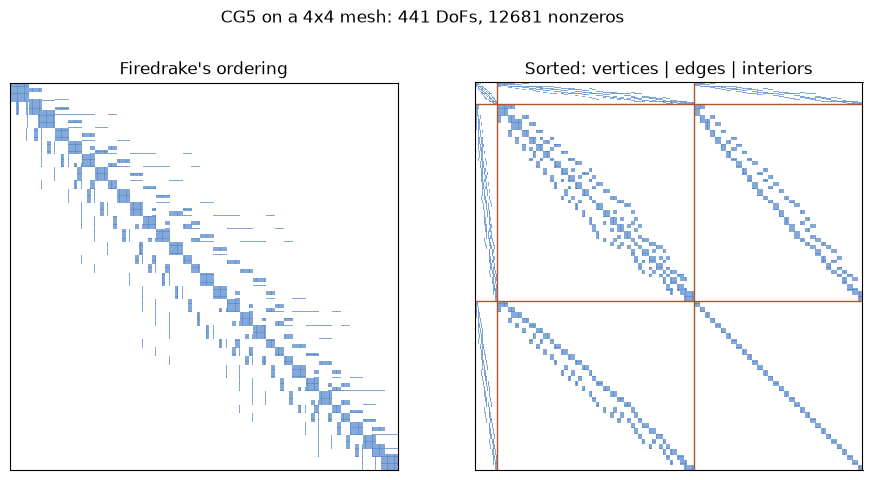

In [14]:
plot_sparsity(p=5, nx=4)

Let's write the sorted matrix in blocks,
$$
A = \begin{pmatrix}
A_{\mathrm{VV}} & A_{\mathrm{VE}} & A_{\mathrm{VI}} \\
A_{\mathrm{EV}} & A_{\mathrm{EE}} & A_{\mathrm{EI}} \\
A_{\mathrm{IV}} & A_{\mathrm{IE}} & A_{\mathrm{II}}
\end{pmatrix},
$$
the interior–interior block $A_{\mathrm{II}}$ is **block diagonal**, with one little dense block per cell.
This aligns with what we saw earlier;
interior DoFs on different cells **cannot communicate**.
In theory then, $A_{\mathrm{II}}$ should be relatively easy to invert.

At higher order $p$, that $A_{\mathrm{II}}$ block takes over.
In 2D, a cell has $O(p^2)$ DoFs, of which only $O(p)$ aren't on the interior.

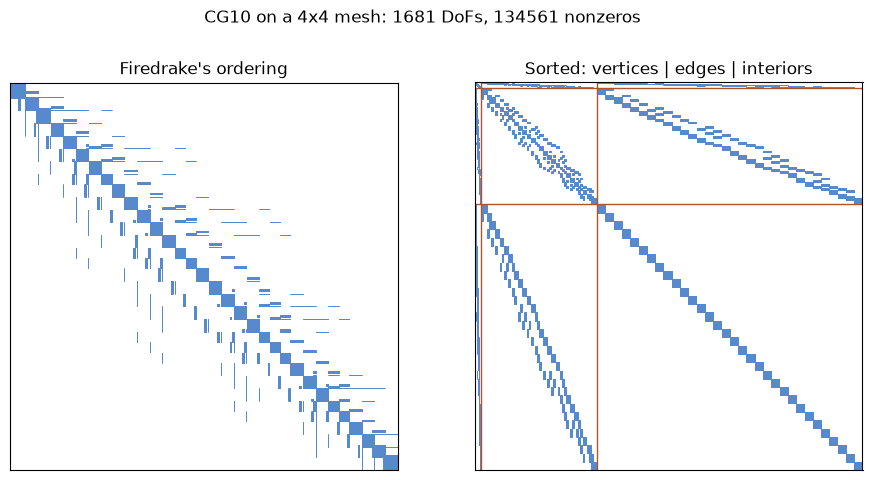

In [15]:
plot_sparsity(p=10, nx=4)

---

## **Schur complements & static condensation**

Let's group the DoFs into ones we'd like to get rid of, $\mathrm{I}$ (cell DoFs), and the rest, $\Gamma$ (edge and vertex DoFs):
$$
\begin{pmatrix} A_{\mathrm{II}} & A_{\mathrm{I}\Gamma} \\ A_{\Gamma\mathrm{I}} & A_{\Gamma\Gamma} \end{pmatrix}
\begin{pmatrix} u_{\mathrm{I}} \\ u_{\Gamma} \end{pmatrix}
=
\begin{pmatrix} b_{\mathrm{I}} \\ b_{\Gamma} \end{pmatrix}.
$$
I'm using $b_{\mathrm{I}}$, $b_{\Gamma}$ to represent some generic RHS data.
We actually make some headway on the first row quite easily:
$$
A_{\mathrm{II}} u_{\mathrm{I}} + A_{\mathrm{I}\Gamma} u_{\Gamma} = b_\mathrm{I}
\quad\implies\quad
A_{\mathrm{II}} u_{\mathrm{I}} = b_{\mathrm{I}} - A_{\mathrm{I}\Gamma} u_\Gamma.
$$
Assuming $A_{\mathrm{II}}$ isn't too hard to invert (it being block diagonal) it's theoretically no problem solve this and recover
$$
u_{\mathrm{I}} = A_{\mathrm{II}}^{-1} (b_{\mathrm{I}} - A_{\mathrm{I}\Gamma} u_\Gamma).
$$
We can substitute that into the second row to get
$$
A_{\Gamma\mathrm{I}} u_{\mathrm{I}} + A_{\Gamma\Gamma} u_{\Gamma} = b_\mathrm{\Gamma}
\quad\implies\quad
\left(A_{\Gamma\Gamma} - A_{\Gamma\mathrm{I}} A_{\mathrm{II}}^{-1} A_{\mathrm{I}\Gamma}\right) u_\Gamma
= b_\Gamma - A_{\Gamma\mathrm{I}} A_{\mathrm{II}}^{-1} b_{\mathrm{I}}.
$$
We call $S := A_{\Gamma\Gamma} - A_{\Gamma\mathrm{I}} A_{\mathrm{II}}^{-1} A_{\mathrm{I}\Gamma}$ the **Schur complement**.
We've reduced that big solve into 2 component:
- **Inverting** $A_{\mathrm{II}}$ *(theoretically easy, by block diagonal structure)*
- **Inverting** $S := A_{\Gamma\Gamma} - A_{\Gamma\mathrm{I}} A_{\mathrm{II}}^{-1} A_{\mathrm{I}\Gamma}$ *(potentially easy-ish, by virtue of being smaller than $A$)*

<!-- In practice, one would solve the smaller system for $u_\Gamma$, then recover $u_{\mathrm{I}}$ through $u_{\mathrm{I}} = A_{\mathrm{II}}^{-1} (b_{\mathrm{I}} - A_{\mathrm{I}\Gamma} u_\Gamma)$. -->
Notably this is **exact**: no approximation, just rearranging.
This is static condensation.

In [16]:
schur_solve_check(p=3, nx=6)

Solved a 289x289 system instead of 361x361.
Difference from the direct solve: 2.5e-14


There are two ways to go about solving the Schur complement problem in $S$:

- **Assemble it**, and hand it off to e.g. a direct solver or AMG.
- **Don't assemble it**, and only ever apply it inside a Krylov method, i.e. solve $A_{\mathrm{II}} y = A_{\mathrm{I}\Gamma} x$ for $y$, then compute $S x = A_{\Gamma\Gamma} x - A_{\Gamma\mathrm{I}} y$.

The former route's simpler, so let's stick with it for now.

### Static condensation in Firedrake

Firedrake has a language for *cell-local* linear algebra: **Slate**.

The TL;DR is that `Tensor(a)` is the cell-local matrix of a form, `.blocks` picks out sub-blocks, and `.inv` is a cell-by-cell inverse. To see it in action, let's first split CG$_p$ into its interior DoFs and the rest:

In [17]:
def split_space(mesh, p):
    """CG_p, split into its cell-interior DoFs and the rest (vertices and edges)."""
    cg = FiniteElement("CG", mesh.ufl_cell(), p)
    return FunctionSpace(mesh, RestrictedElement(cg, "interior")) * FunctionSpace(mesh, RestrictedElement(cg, "facet"))

We can then define our residual:

In [18]:
def condensed_helmholtz(mesh, p):
    """Helmholtz on CG_p = interior ⊕ facet, u = 0 on the boundary."""
    W = split_space(mesh, p)
    # Functions
    uI, uF = TrialFunctions(W)
    vI, vF = TestFunctions(W)
    # Stick interior and facet components back together
    u, v = uI + uF, vI + vF
    # Residual and BCs
    a = (inner(grad(u), grad(v)) + u*v)*dx
    L = forcing(mesh)*v*dx
    bcs = DirichletBC(W.sub(1), 0, "on_boundary")
    return W, a, L, bcs

Now we could all the condensation stuff from above by hand (if we really wanted):

In [19]:
def static_condensation_by_hand(p=3, nx=8):
    mesh = UnitSquareMesh(nx, nx)
    W, a, L, _ = condensed_helmholtz(mesh, p)

    # Slate lets us split the LHS matrix and RHS vector
    A, F = Tensor(a), Tensor(L)
    AII, AIF, AFI, AFF = A.blocks[0, 0], A.blocks[0, 1], A.blocks[1, 0], A.blocks[1, 1]
    FI, FF = F.blocks[0], F.blocks[1]
    AII_inv = AII.inv # We can invert this block fine!

    # Solve for u_F
    VF = W.sub(1).collapse()
    bcF = DirichletBC(VF, 0, "on_boundary")
    S = assemble(AFF - AFI * AII_inv * AIF, bcs=bcF)
    r = assemble(FF - AFI * AII_inv * FI)
    r.dat.data[bcF.nodes] = 0
    uF = Function(VF)
    solve(S, uF, r, solver_parameters={"ksp_type": "preonly", "pc_type": "lu"})

    # Recover u_I
    uI = assemble(AII.inv * (FI - AIF * AssembledVector(uF)))

    # (Quick direct CG_p run for comparison...)
    V = FunctionSpace(mesh, "CG", p)
    u = Function(V)
    solve(helmholtz(V) == forcing(mesh)*TestFunction(V)*dx, u, bcs=DirichletBC(V, 0, "on_boundary"))
    print(f"Global solve: {VF.dim()} unknowns instead of {V.dim()}.")
    print(f"||u_condensed - u_CG|| = {norm(uI + uF - u):.1e}")

static_condensation_by_hand()

Global solve: 497 unknowns instead of 625.
||u_condensed - u_CG|| = 5.2e-16


There is (of course) an easier way.
You can just let Firedrake do this for you, with the `SCPC` preconditioner: it eliminates a field cell by cell, then hands the condensed system to your solver of choice.

In [20]:
SOLVERS = {
    "lu": {"ksp_type": "preonly", "pc_type": "lu"},
    "gamg": {"ksp_type": "cg", "pc_type": "gamg", "ksp_rtol": 1e-10},
}


def sc_params(solver):
    """Eliminate field 0 cell by cell, then hand what's left to the given solver."""
    return {
        "mat_type": "matfree",  # Stop! Don't assemble the whole mixed system!
        "ksp_type": "preonly",  # Exact solver (a.k.a. "one iterate of preconditioner")
        "pc_type": "python",  # We're going to use a solver defined a Python...
        "pc_python_type": "firedrake.SCPC",  # ...the firedrake.SCPC solver
        "pc_sc_eliminate_fields": "0",  # Eliminate field 0 (interior DoFs)
        "condensed_field": SOLVERS[solver],  # Solve the rest using SOLVERS[solver]
    }

By default it assembles $S$.
For the never-assemble version, add `"mat_type": "matfree"` to the `condensed_field` options.
<!-- (you'd then need a preconditioner that doesn't need the matrix entries) -->

### Scaling in $p$

Now the payoff.
Here's CG$_p$ on a $32 \times 32$ mesh, solved with CG preconditioned by algebraic multigrid (GAMG), with and without condensation.

p = 1: unknowns   1089 ->   1089 | nonzeros     7361 ->     7361 | iterations   14 ->   14 | time 0.002s -> 0.002s


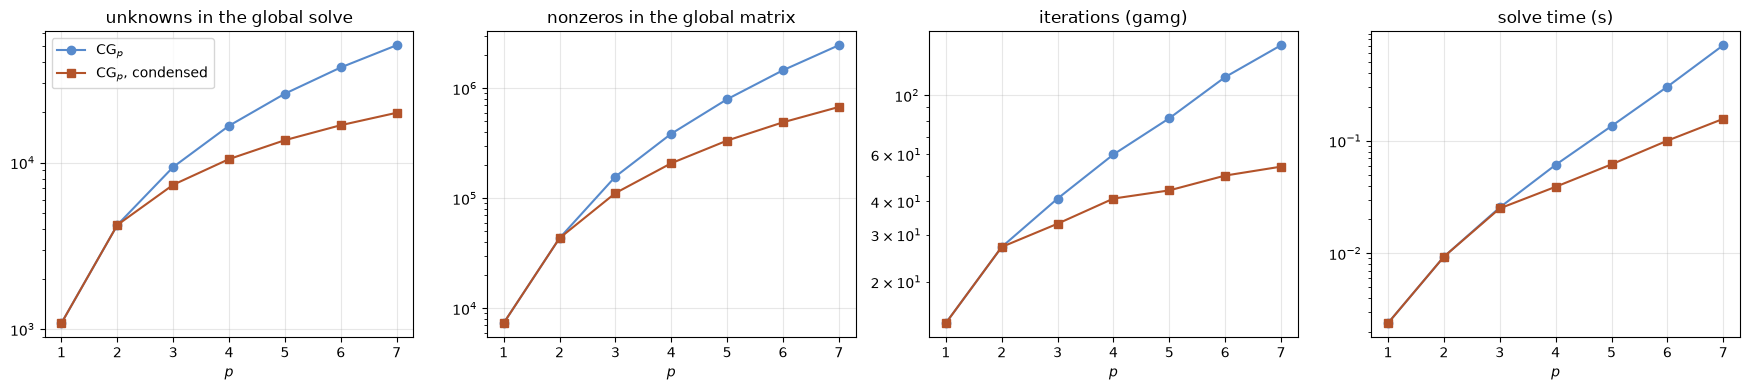

p = 2: unknowns   4225 ->   4225 | nonzeros    43521 ->    43521 | iterations   27 ->   27 | time 0.009s -> 0.009s


p = 3: unknowns   9409 ->   7361 | nonzeros   157633 ->   111649 | iterations   41 ->   33 | time 0.026s -> 0.025s


p = 4: unknowns  16641 ->  10497 | nonzeros   386561 ->   208533 | iterations   60 ->   41 | time 0.061s -> 0.039s


p = 5: unknowns  25921 ->  13633 | nonzeros   795841 ->   334993 | iterations   82 ->   44 | time 0.136s -> 0.062s


p = 6: unknowns  37249 ->  16769 | nonzeros  1459201 ->   491029 | iterations  117 ->   50 | time 0.304s -> 0.101s


p = 7: unknowns  50625 ->  19905 | nonzeros  2462657 ->   676641 | iterations  154 ->   54 | time 0.710s -> 0.157s


In [21]:
condensation_scaling()

Unknowns and nonzeros grow **much** more slowly once we condense.
In 2D, the full system has $O(p^2)$ DoFs per cell;
the condensed one only $O(p)$.

<!-- The iteration count is the nice surprise: the condensed system is **better conditioned**, and its iteration count grows much more slowly with $p$. -->
<!-- The end result is roughly a $4\times$ speed-up by $p = 7$, even including all the local work. -->

N.B. With direct LU, the story isn't quite as good:

p = 1: unknowns   1089 ->   1089 | nonzeros     7361 ->     7361 | iterations    1 ->    1 | time 0.001s -> 0.001s


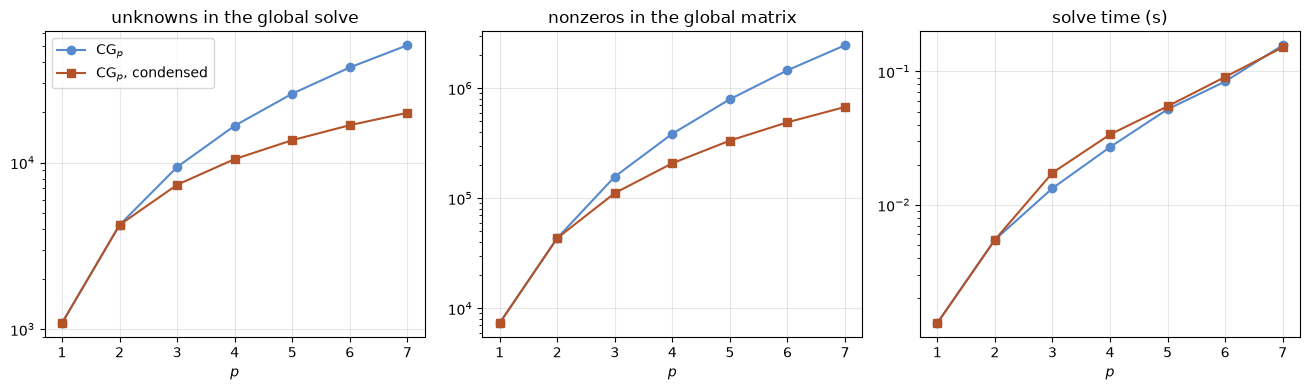

p = 2: unknowns   4225 ->   4225 | nonzeros    43521 ->    43521 | iterations    1 ->    1 | time 0.005s -> 0.005s


p = 3: unknowns   9409 ->   7361 | nonzeros   157633 ->   111649 | iterations    1 ->    1 | time 0.013s -> 0.017s


p = 4: unknowns  16641 ->  10497 | nonzeros   386561 ->   208533 | iterations    1 ->    1 | time 0.027s -> 0.034s


p = 5: unknowns  25921 ->  13633 | nonzeros   795841 ->   334993 | iterations    1 ->    1 | time 0.052s -> 0.055s


p = 6: unknowns  37249 ->  16769 | nonzeros  1459201 ->   491029 | iterations    1 ->    1 | time 0.084s -> 0.091s


p = 7: unknowns  50625 ->  19905 | nonzeros  2462657 ->   676641 | iterations    1 ->    1 | time 0.157s -> 0.152s


In [22]:
condensation_scaling(solver="lu")

Why is that?
Well, a good ordering for LU should eliminate the cell interiors first anyway, since they create no fill.
In other words, PETSc's direct solver was kind of *already* doing static condensation for us anyway, behind our back!

---

## **Hybridisation**

Here's a thought: ***What if* every DoF were a cell-interior DoF?**
$$
A = (A_{\mathrm{II}})
$$
Then we could condense *everything*!

Here's a rough outline of the alternative plan:

1. **Break the space:** just throw away any inter-element continuity for now, reduce to DG, no more edge or vertex DoFs, every DoF belongs to exactly one cell.
2. **Glue it back together with a Lagrange multiplier**: this would be a new variable we introduce, just living on the facets.
3. **Condense out the interior DoFs**: thus we're just solving a problem on the multiplier.

This is **hybridisation**.

### Let's hybridise CG!

Since we've been considering CG$_p$ up to here, let's stick there for our first try.

Hybridisation is (essentially) inspired by writing CG$_p$ as
$$
CG_p = \{u \in DG_p : \text{on each facet, } [\![u]\!] = u_+ - u_- = 0\}.
$$

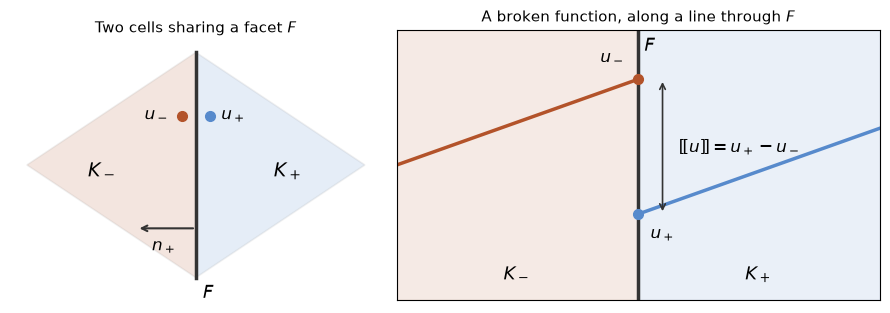

In [23]:
plot_jump()

Here $u_\pm$ and $u_-$ are the values of $u$ on $F$ seen from either side.
<!-- , and $n_+$ is the unit normal pointing out of $K_+$. -->
Alternatively, since $[\![u]\!]$ is in DG$_p$ on each facet, we can write this variationally:
$$
CG_p = \Big\{u \in DG_p : \text{on each facet }F, \int_F [\![u]\!]q = 0 \text{ for all } q \in DG_p(F)\Big\}.
$$
So, we can break CG$_p$ into DG$_p$, then restore the continuity between cells with a multiplier in DG$_p$ on each facet, enforcing the jump $[\![u]\!] = u_+ - u_- = 0$.

*Soooo... This doesn't work.*

Why?
Well, it's a bit technical, but the trouble is the **corners**.
A vertex is shared by a whole patch of cells.
After breaking, each of them would get its own copy of that vertex DoF.
The facet multipliers then demand that each neighbouring pair of copies agree.
Go round the vertex and you find you've imposed one equality too many: the constraints are **redundant**.

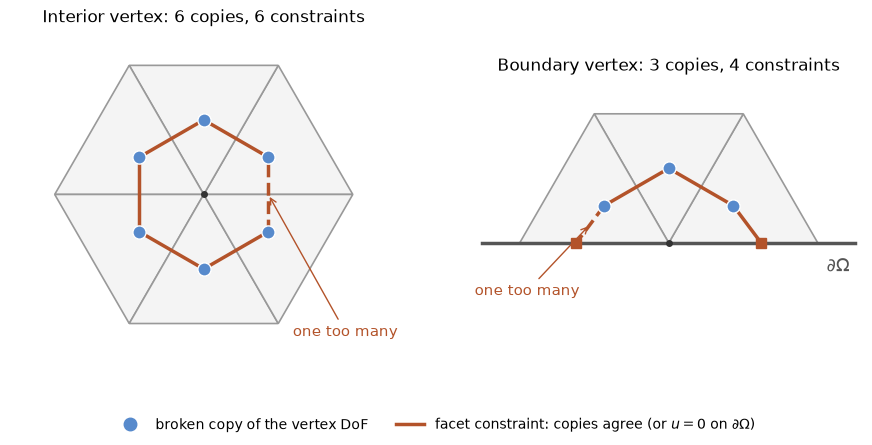

In [24]:
plot_vertex_patches()

You only need 5 constraints to impose equality between 6 variables.
Which constraint we call redundant is arbitrary; the point is that there's always one too many, at every vertex.
<!-- Here it is for an interior vertex and a boundary vertex (where the boundary facets pin the copies to $u = 0$). -->

Essentially, the jump map on DG$_p$ is *into* DG$_p$(facets), but not *onto*.
You fail inf-sup on the saddle-point system.

In [25]:
naive_hybrid_cg_nullity(p=2, nx=3)

Saddle-point matrix: 207x207, nullity 16.
Number of vertices in the mesh: 16.


In general, **you can't hybridise elements with DoFs at the corners** (or, at least, it's non-trivial; c.f. ongoing work with Olav!).
So we need a different space.

Well, the standard choice is to use a **mixed formulation** with H(div) elements, like Raviart–Thomas: those only have DoFs on facets and interiors.
I don't want to get bogged down in mixed formulations and H(div) though, so let's find a primal space with no corner DoFs...

### Let's hybridise Crouzeix–Raviart!

The **Crouzeix–Raviart** space CR$_p$ is the set of piecewise polynomials of degree $p$ whose jumps are orthogonal to polynomials of degree $p-1$ on every facet:
$$
CR_p = \Big\{u \in DG_p : \text{on each facet }F, \int_F [\![u]\!]q = 0 \text{ for all } q \in DG_{p-1}(F)\Big\}.
$$
We're just going to lower that imposed continuity by one degree.

Two notes:
- **CR$_p$ is weakly conforming**: it's not actually *continuous*... but it's "continuous enough" to work on Poisson.
- **CR$_p$ is only well-defined at odd $p$**: for technical *(but surprisingly fun)* reasons that I won't go into.

In [26]:
try:
    FunctionSpace(demo_mesh, "CR", 2)
except ValueError as e:
    print(e)

Crouzeix-Raviart only defined for odd degree


Its DoFs are:
- **Cells:** $\tfrac{(p-1)(p-2)}{2}$
- **Facets:** $p$ (moments against $DG_{p-1}$)
- **Vertices:** Nothing!

With no DoFs at vertices, it's ready to be hybridised!

Here's CR$_1$ and CR$_3$:

In [27]:
coupling_widget(helmholtz(FunctionSpace(demo_mesh, "CR", 1)), title="CR1")

In [28]:
coupling_widget(helmholtz(FunctionSpace(demo_mesh, "CR", 3)), title="CR3")

### Break it, then glue it back together

To hybridise, we use that characterisation of CR$_p$:
$$
CR_p = \Big\{u \in DG_p : \text{on each facet }F, \int_F [\![u]\!]q = 0 \text{ for all } q \in DG_{p-1}(F)\Big\}.
$$

<!-- So, we first **break** CR$_p$: keep the same local DoFs, but give each cell its own copy of every facet DoF.
The broken space is just $\mathbb{P}_p(T_h)$, i.e. DG$_p$, only written in CR's basis.

To **glue** it back together, we want to impose CR's continuity condition $\int_F [\![u]\!]\, q = 0$ for all $q \in \mathbb{P}_{p-1}(F)$.
That's a **constraint**, so we enforce it with a **Lagrange multiplier**
$$
\lambda \in M := \mathbb{P}_{p-1}(F_h),
$$
a polynomial of degree $p-1$ on each facet, **discontinuous from one facet to the next**, and living **only on the skeleton** of the mesh (`"HDiv Trace"` in Firedrake). -->

The hybridised problem enforces that continuity with a Lagrange multiplier:
> Find $(u, p) \in DG_p(\text{cells}) \times DG_{p-1}(\text{facets})$ such that
> $$
> \begin{aligned}
> \sum_K \int_K \nabla u \!\cdot\! \nabla v + uv \;+\; \sum_F \int_F [\![v]\!]\, p &= \int_\Omega fv, \\
> \sum_F \int_F [\![u]\!]\, q &= 0,
> \end{aligned}
> $$
> for all $(v, q) \in DG_p(\text{cells}) \times DG_{p-1}(\text{facets})$.

The second equation enforces $u \in CR_p$;
the first equation adds the adjoint (testing with $v \in CR_p$ kills the $p$ term).
So *(just like static condensation)* $u$ is **exactly the CR$_p$ solution**, not an approximation of it.

<!-- This is a **saddle-point problem**, so as usual we need an **inf-sup condition** between $\mathbb{P}_p(\mathcal{T}_h)$ and $M$.
Here it holds, because $M$ is exactly dual to CR's facet DoFs, with no corners to over-constrain. -->

Here are the DoFs before and after, for $p = 1$ and $p = 3$: the **DG$_p$ DoFs** in blue, the **multiplier DoFs** in brown.

In [29]:
for p in [1, 3]:
    W, a, L = hybrid_cr(demo_mesh, p)
    coupling_widget(a, title=f"DG{p} + multiplier", fields=[f"DG{p}", f"multiplier (degree {p - 1})"])

Nothing crosses a facet, except through $p$. In matrix form:

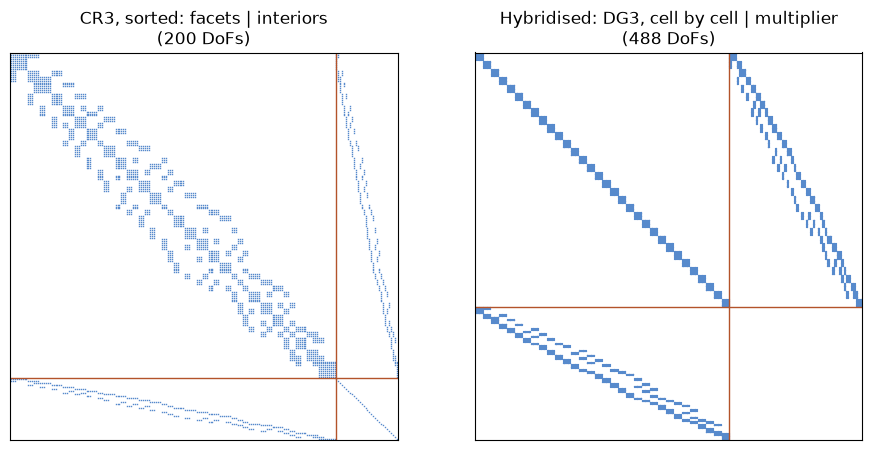

In [30]:
plot_hybrid_sparsity(p=3, nx=4)

<!-- Without hybridisation, only the interiors form a block-diagonal chunk, and for CR$_3$ that's one DoF per cell. -->
After hybridising, the DG block is block diagonal, with one dense block per cell: most of the matrix.
The multipliers only appear in the border;
the multiplier–multiplier block is empty.

So every DoF of $u$ is now a cell-interior DoF.
Similarly to the above therefore, we can construct a Schur complement to condense **all of $u$** away, leaving a global system for $p$ only.

<!-- N.B. The `jump_s` in `hybrid_cr` is a Firedrake implementation detail: Slate assembles facet integrals cell by cell, so the sign of the jump must be fixed by the facet itself (see its docstring).
With UFL's plain `jump(v)`, the condensed solve gives the wrong answer **without any error**. -->

<!-- Let's check that we really get the CR solution back: -->

In [31]:
hybrid_check(ps=(1, 3, 5), nx=8)

p = 1: ||u_hybrid - u_CR|| = 2.4e-15   (multiplier: 208 unknowns, CR: 208)


p = 3: ||u_hybrid - u_CR|| = 2.7e-15   (multiplier: 624 unknowns, CR: 752)


p = 5: ||u_hybrid - u_CR|| = 7.4e-13   (multiplier: 1040 unknowns, CR: 1808)


<!-- Machine precision. -->

Note also the number of unknowns we end up solving for: $p$ per facet, the same as what we'd get by statically condensing CR$_p$.

### Scaling in $p$

p = 1: unknowns   3136 ->   3136 | nonzeros    11328 ->    15424 | iterations   14 ->  214 | time 0.004s -> 0.023s


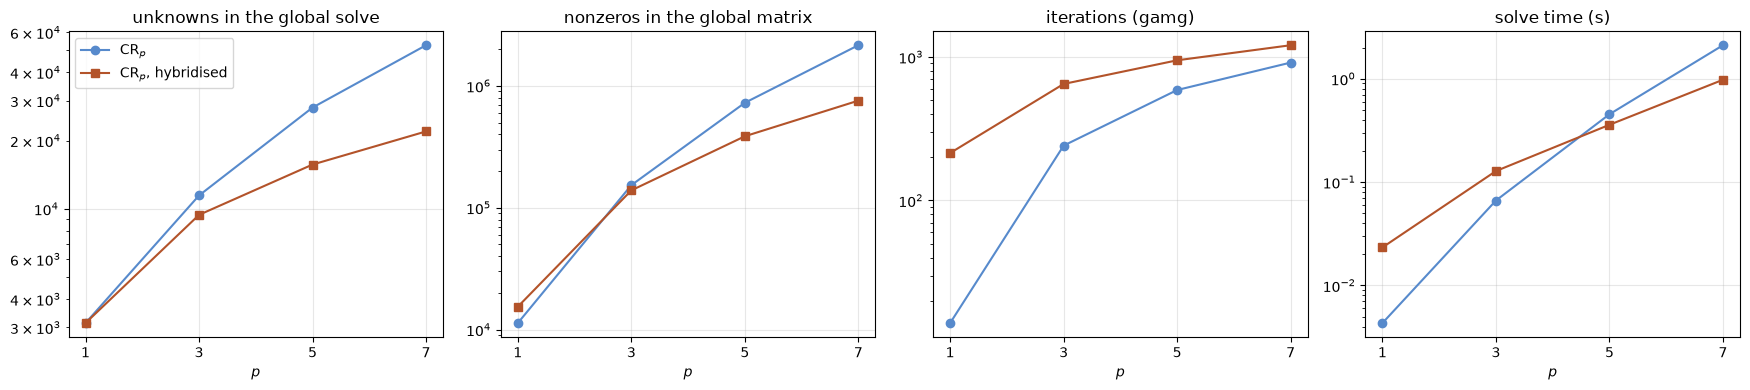

p = 3: unknowns  11456 ->   9408 | nonzeros   153152 ->   138816 | iterations  241 ->  648 | time 0.066s -> 0.128s


p = 5: unknowns  27968 ->  15680 | nonzeros   725528 ->   385600 | iterations  588 ->  947 | time 0.453s -> 0.359s


p = 7: unknowns  52672 ->  21952 | nonzeros  2152310 ->   755776 | iterations  913 -> 1206 | time 2.110s -> 0.977s


In [32]:
hybridisation_scaling()

Again, **unknowns and nonzeros** grow much more slowly in $p$, and for $p \ge 5$ the hybridised solve wins on time.

The iteration counts are worse, though.
The multiplier system isn't the kind of operator GAMG was designed for, and preconditioning it well is a story of its own.
The win here comes purely from the global system being so much smaller.

---

## **Discussion:** *Which, when?*

| | **Static condensation** | **Hybridisation** |
| --- | --- | --- |
| **Which elements?** | Works **immediately** for **any element** with interior DoFs | Works, in theory, for **any element** (c.f. ongoing work with Olav on hybridised FES), but **the corners are non-trivial** |
| **Extra DoFs?** | **None** | The **multiplier**, on the facets |
| **Local problems** | **Dirichlet problems**: always invertible | **Neumann problems**: need something (like a zeroth-order term) to be invertible |
| **Piola transforms** | Wherever the element needs them | **None**: the space is broken |
| **Bases** | Have to respect inter-element continuity | **Sparse bases out of the box**: no continuity for the basis to respect |

### The catch: local invertibility

To condense away $u$ in hybridisation, we invert the broken matrix **cell by cell**.
Each cell block is a **Neumann problem** on that cell.
Without the zeroth-order term, constants are in its kernel, and it's **singular**:

In [33]:
local_block_nullity(p=3, nx=3)

        Poisson: nullity  18   (18 cells)
 good Helmholtz: nullity   0   (18 cells)


One null vector per cell for pure Poisson.
That's why we've been doing *good* Helmholtz!

Static condensation never has this problem: interior DoFs vanish on the cell boundary, so the interior blocks are Dirichlet problems, invertible even for pure Poisson.

### Sparse bases

On sparse bases: here's one cell of broken CR$_5$ in CR's own basis, against an L²-orthogonal basis (`variant="integral"`).
Same space, same solution, very different local blocks:

In [34]:
basis_comparison(p=5, nx=8)

       basis | stiffness |  mass | u-λ coupling   (nonzeros on one cell)


          CR |  397/441  |   339 |    69/315   


    integral |  398/441  |    21 |   302/315   



Same solution either way: ||u_CR-basis - u_integral-basis|| = 1.4e-12


The orthogonal basis makes the mass matrix **diagonal** (the stiffness matrix stays dense on a general cell); CR's basis instead makes the coupling to the multiplier sparse.

(N.B. Slate inverts local blocks densely regardless, so in Firedrake as it stands this doesn't speed anything up.)

---

## **Extras** *(If time...)*

### What is the multiplier?

Integrate by parts on each cell against the exact solution and compare with the first equation: $\lambda$ approximates the **normal flux**,
$$
\lambda \approx -\nabla u \cdot \nu_F,
$$
where $\nu_F$ is the unit normal of facet $F$, oriented the same way as the jump.
That's no accident: it's the force needed to hold the broken pieces together.

In [35]:
flux_check(p=3)

nx =  4: ||u - u_exact|| = 3.19e-04, ||λ + ∇u_exact·ν|| = 1.83e-02
nx =  8: ||u - u_exact|| = 1.94e-05, ||λ + ∇u_exact·ν|| = 2.56e-03   rates: 4.04, 2.84
nx = 16: ||u - u_exact|| = 1.19e-06, ||λ + ∇u_exact·ν|| = 3.58e-04   rates: 4.03, 2.84


nx = 32: ||u - u_exact|| = 7.36e-08, ||λ + ∇u_exact·ν|| = 5.22e-05   rates: 4.01, 2.78


So hybridisation gives you a **flux on every facet for free**, which is a natural route into **local (cellwise) structures**, e.g. local conservation: summing the first equation with $v = 1$ on a single cell $K$ gives
$$
\int_K u + \int_{\partial K} \lambda\, (\nu_F \cdot n_K) = \int_K f,
$$
an exact cellwise balance law.

### Other things we didn't cover

- **Mixed Poisson** with H(div) elements (Raviart–Thomas), the classic hybridisation demo.
  There, the multiplier approximates the *trace* of $u$, and the local problems are Dirichlet problems.
  In Firedrake: `firedrake.HybridizationPC`.
- **Post-processing** for an extra order of accuracy (Arnold & Brezzi): a special trick for mixed Poisson, not something hybridisation gives you in general.
- The **unified hybridisation** framework of Cockburn, Gopalakrishnan & Lazarov (2009), and **HDG**.

### References

- **B. Fraeijs de Veubeke**, Displacement and equilibrium models in the finite element method, in *Stress Analysis*, Wiley (1965)
- **D. N. Arnold** and **F. Brezzi**, Mixed and nonconforming finite element methods: implementation, postprocessing and error estimates, *M2AN*, 19 (1985)
- **M. Crouzeix** and **P.-A. Raviart**, Conforming and nonconforming finite element methods for solving the stationary Stokes equations I, *RAIRO*, 7 (1973)
- **M. Fortin** and **M. Soulie**, A non-conforming piecewise quadratic finite element on triangles, *IJNME*, 19 (1983)
- **B. Cockburn**, **J. Gopalakrishnan** and **R. Lazarov**, Unified hybridization of discontinuous Galerkin, mixed, and continuous Galerkin methods for second order elliptic problems, *SINUM*, 47 (2009)
- **T. H. Gibson**, **L. Mitchell**, **D. A. Ham** and **C. J. Cotter**, Slate: extending Firedrake's domain-specific abstraction to hybridized solvers for geoscience and beyond, *GMD*, 13 (2020)